# 05 · Demand findings for operations

What explains the demand of Citi Bike stations, and what should operations do about it?
Every number here comes from the same 12 months (Oct 2025 to Sep 2026) and the same 45,226,146 clean trips as the model, and they are written to `data/results/findings_*.csv` and `findings_numbers.json`, which `docs/findings.md` quotes.

| Part | Question | Cause in the project brief |
| --- | --- | --- |
| 1 | Which stations lose or gain bikes at the rush hours? | hour, station type |
| 2 | Who rides, members or casual riders, and on which bikes? | user type |
| 3 | How much do rain, cold and snow cut demand? | weather |
| 4 | Where can the forecast be trusted, and what does the model add to a station profile? | uncertainty |

**Method.** Parts 1 to 3 are descriptive and use all 12 months.
Part 4 scores the shipped model (v3, refit through Sep 16) on the test block of `docs/evaluation.md` (Sep 17 to 30), which was not used to choose anything, against the baseline to beat.
Thresholds of the station types are round numbers chosen by eye from the distributions of the station features, not tuned to any score.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm_api
from scipy import stats as sps

import citibike_eval as ce
import citibike_findings as cf
import citibike_model as cm

REPO = Path('..')
DATA_DIR = Path('data_procesada')
RESULTS = REPO / 'data' / 'results'
CACHE = REPO / 'tmp' / 'cache'
WORK = REPO / 'tmp' / 'v3'
IMG = REPO / 'docs' / 'img'
IMG.mkdir(parents=True, exist_ok=True)
N = {}  # every headline number, written to findings_numbers.json at the end

# station types: round thresholds chosen by eye, not tuned
AM, PM = slice(6, 10), slice(16, 20)  # 06:00 to 10:00 and 16:00 to 20:00
BIG = 5  # bikes of net change in the morning peak
LOW = 10  # departures per workday
LEISURE = 1.15  # free-day departures over workday departures
MIN_WORK_DAYS, MIN_FREE_DAYS = 100, 40  # full days needed to describe a station


def save(df, name):
  df.to_csv(RESULTS / name, index=False)
  return df


def style():
  plt.rcParams.update({
      'font.size': 12, 'axes.titlesize': 12, 'axes.labelsize': 12, 'xtick.labelsize': 10, 'ytick.labelsize': 10, 'legend.fontsize': 11,
      'axes.spines.top': False, 'axes.spines.right': False, 'axes.titleweight': 'normal', 'axes.titlelocation': 'left',
      'legend.frameon': False, 'savefig.dpi': 200, 'savefig.bbox': 'tight', 'figure.dpi': 100, 'pdf.fonttype': 42
  })


style()
# colour-blind safe palette (Okabe-Ito), one colour per entity
C_ORIGIN, C_DEST, C_LEISURE, C_BAL = '#D55E00', '#0072B2', '#009E73', '#7F7F7F'
C_MODEL, C_BASE, C_ACTUAL, C_RAIN = '#009E73', '#8C8C8C', '#111111', '#56B4E9'
print('ready')

ready


In [2]:
data = ce.load_processed(DATA_DIR, cache_dir=CACHE)
n, D = data.n_est, data.n_days
free = data.daytype.astype(int)  # 1 = weekend or federal holiday
station_mix, city_mix, clean_trips = cf.rider_mix(Path('.'), DATA_DIR, REPO / 'tmp' / 'findings')
departures_model = int(np.asarray(data.Y[..., :2], dtype=np.int64).sum())
in_model = station_mix[station_mix['station_id'].isin(set(data.est['station_id']))]['n'].sum()
assert int(in_model) == departures_model, 'the rider-type counts must equal the departures of the demand tables'
N['clean_trips'] = int(clean_trips)
N['stations_model'] = int(n)
N['days_free'], N['days_work'] = int(free.sum()), int((1 - free).sum())
print(f'{clean_trips:,} clean trips, {in_model:,} departures at the {n:,} model stations (equal to the demand tables)')

45,226,146 clean trips, 45,225,710 departures at the 2,515 model stations (equal to the demand tables)


## 1. Which stations lose or gain bikes at the rush hours

For every station: the mean departures and arrivals per hour on workdays and on weekends and holidays, over the days on which the station was active all day.
`net_am` is arrivals minus departures between 06:00 and 10:00 on a workday, so a negative value is a station that loses bikes.

In [3]:
dep_h = np.zeros((n, 2, 24))
arr_h = np.zeros((n, 2, 24))
n_full = np.zeros((n, 2))
for a in range(0, n, 250):
  b = min(n, a + 250)
  Y = np.asarray(data.Y[a:b], dtype=np.float32).reshape(b - a, D, 24, 4, 4)
  full = np.asarray(data.act[a:b]).reshape(b - a, D, 96).all(2)
  dep, arr = (Y[..., 0] + Y[..., 1]).sum(3), (Y[..., 2] + Y[..., 3]).sum(3)
  for t in (0, 1):
    m = full & (free == t)[None, :]
    n_full[a:b, t] = m.sum(1)
    dep_h[a:b, t] = np.einsum('nd,ndh->nh', m, dep)
    arr_h[a:b, t] = np.einsum('nd,ndh->nh', m, arr)
dep_h, arr_h = dep_h / np.maximum(n_full, 1)[..., None], arr_h / np.maximum(n_full, 1)[..., None]

est = data.est[['station_idx', 'station_id', 'name', 'lat', 'lng']].copy()
est['n_work'], est['n_free'] = n_full[:, 0], n_full[:, 1]
est['dep_work'], est['dep_free'] = dep_h[:, 0].sum(1), dep_h[:, 1].sum(1)
est['net_am'] = (arr_h[:, 0, AM] - dep_h[:, 0, AM]).sum(1)
est['net_pm'] = (arr_h[:, 0, PM] - dep_h[:, 0, PM]).sum(1)
est['free_ratio'] = est['dep_free'] / np.maximum(est['dep_work'], 1e-9)
sm = station_mix.groupby('station_id').apply(
    lambda g: pd.Series(dict(n=g.n.sum(), casual=g.loc[g.member == 0, 'n'].sum(), electric=g.loc[g.electric == 1, 'n'].sum())),
    include_groups=False)
est = est.merge(sm, left_on='station_id', right_index=True, how='left')
est['casual_share'], est['electric_share'] = est['casual'] / est['n'], est['electric'] / est['n']

typed = (est['n_work'] >= MIN_WORK_DAYS) & (est['n_free'] >= MIN_FREE_DAYS)


def station_type(r):
  if r.dep_work < LOW:
    return 'low use'
  if r.net_am <= -BIG:
    return 'origin'
  if r.net_am >= BIG:
    return 'destination'
  return 'leisure' if r.free_ratio >= LEISURE else 'balanced'


est['type'] = 'not typed'
est.loc[typed, 'type'] = est[typed].apply(station_type, axis=1)
T = est[typed]
rows = []
for t in ['origin', 'destination', 'leisure', 'balanced', 'low use']:
  g = T[T['type'] == t]
  rows.append(dict(type=t, stations=len(g), share_workday_trips=g.dep_work.sum() / T.dep_work.sum(),
                   share_free_day_trips=g.dep_free.sum() / T.dep_free.sum(), net_am=g.net_am.mean(), net_pm=g.net_pm.mean(),
                   free_ratio=g.dep_free.sum() / g.dep_work.sum(), casual_share=g.casual.sum() / g.n.sum(),
                   electric_share=g.electric.sum() / g.n.sum(), departures_per_workday=g.dep_work.mean()))
types = save(pd.DataFrame(rows), 'findings_station_types.csv')
save(est.loc[typed, ['station_id', 'name', 'type', 'net_am', 'net_pm', 'dep_work', 'dep_free', 'free_ratio', 'casual_share',
                     'electric_share']].round(4), 'findings_station_profiles.csv')
N['stations_typed'] = int(typed.sum())
N['types'] = types.set_index('type').round(4).to_dict('index')
N['big_movers'] = int((T.net_am.abs() >= BIG).sum())
N['big_movers_share'] = float((T.net_am.abs() >= BIG).mean())
for t, sign in (('origin', lambda x: x >= 0), ('destination', lambda x: x <= 0)):
  g = T[T['type'] == t]
  N[f'{t}_reverse_share'] = float(sign(g.net_pm).mean())
N['top_destinations'] = T.nlargest(3, 'net_am')[['name', 'net_am', 'net_pm']].round(1).to_dict('records')
N['top_origins'] = T.nsmallest(3, 'net_am')[['name', 'net_am', 'net_pm']].round(1).to_dict('records')
types.round(3)

,type,stations,share_workday_trips,share_free_day_trips,net_am,net_pm,free_ratio,casual_share,electric_share,departures_per_workday
0,origin,460,0.377,0.413,-13.859,8.868,0.909,0.158,0.710,108.437
1,destination,306,0.317,0.258,19.729,-16.342,0.676,0.175,0.723,136.928
2,leisure,78,0.028,0.044,-0.363,1.366,1.290,0.254,0.715,47.640
3,balanced,843,0.252,0.259,-0.849,0.264,0.853,0.174,0.735,39.510
4,low use,650,0.026,0.026,0.341,1.092,0.860,0.241,0.791,5.193


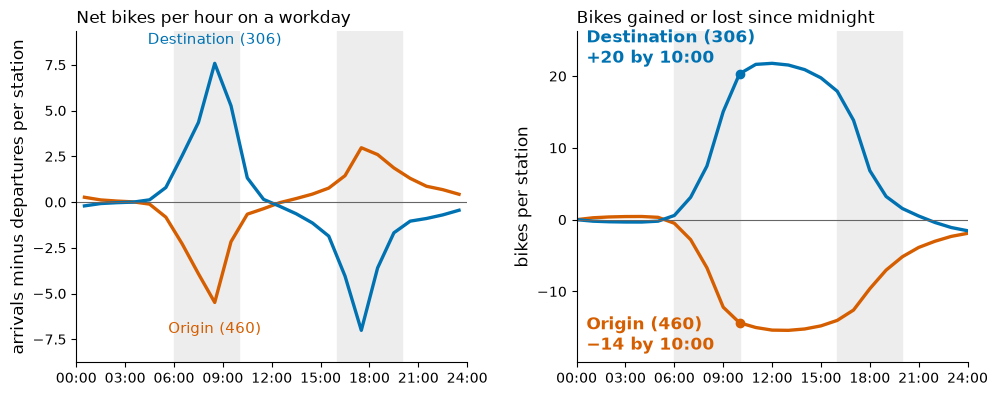

In [4]:
def fig_tide(lang):
  L = LABELS[lang]
  fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.3), sharex=True)
  idx = {t: np.nonzero((est['type'] == t).values)[0] for t in ('origin', 'destination')}
  for ax, cumulative in zip(axes, (False, True)):
    for t, color in (('origin', C_ORIGIN), ('destination', C_DEST)):
      net = (arr_h[idx[t], 0, :] - dep_h[idx[t], 0, :]).mean(0)
      if cumulative:
        y, x = np.concatenate([[0], np.cumsum(net)]), np.arange(25)
      else:
        y, x = net, np.arange(24) + 0.5
      ax.plot(x, y, color=color, lw=2.4)
      if not cumulative:
        yl = float(np.interp(8.5, x, y))
        ax.annotate(f"{L[t]} ({len(idx[t])})", (8.5, yl), textcoords='offset points', xytext=(0, 14 if yl > 0 else -22), ha='center',
                    color=color, fontsize=11)
      if cumulative:
        text = f"{L[t]} ({len(idx[t])})\n{y[10]:+.0f} {L['by10']}".replace('-', '\u2212')
        ax.text(0.6, y[10] + (3.6 if y[10] > 0 else -1.7), text, ha='left', va='center', color=color, fontsize=12, fontweight='bold')
        ax.plot([10], [y[10]], 'o', color=color, ms=6)
    for lo, hi in ((6, 10), (16, 20)):
      ax.axvspan(lo, hi, color='0.93', zorder=0)
    ax.axhline(0, color='0.4', lw=0.8)
    ax.set_xticks(range(0, 25, 3))
    ax.set_xticklabels([f'{h:02d}:00' for h in range(0, 25, 3)])
    ax.set_xlim(0, 24)
    ax.margins(y=0.12)
  axes[0].set_title(L['tide_a'])
  axes[1].set_title(L['tide_b'])
  axes[0].set_ylabel(L['tide_ya'])
  axes[1].set_ylabel(L['tide_yb'])
  fig.subplots_adjust(wspace=0.28)
  return fig


LABELS = {
    'en': dict(origin='Origin', destination='Destination', tide_a='Net bikes per hour on a workday',
               tide_b='Bikes gained or lost since midnight', tide_ya='arrivals minus departures per station',
               tide_yb='bikes per station', by10='by 10:00'),
    'es': dict(origin='Origen', destination='Destino', tide_a='Bicis netas por hora en un día laborable',
               tide_b='Bicis ganadas o perdidas desde la medianoche', tide_ya='llegadas menos salidas por estación',
               tide_yb='bicis por estación', by10='a las 10:00'),
}
for lang in ('en', 'es'):
  f = fig_tide(lang)
  f.savefig(IMG / f'findings_tide_{lang}.png')
  if lang == 'en':
    plt.show()
  plt.close(f)

## 2. Who rides: members and casual riders, classic and electric bikes

The trip files tell members from casual riders, which the demand tables of the model do not keep.
The counts below come from a second pass over the raw files with the same filters, and they add up to the same departures (checked above).

In [5]:
days_by_type = {0: N['days_work'], 1: N['days_free']}
c = city_mix.merge(pd.DataFrame({'day': np.arange(D), 'free': free}), on='day')
c['month'] = pd.DatetimeIndex(data.days)[c['day'].values].strftime('%Y-%m')
by_hour = c.groupby(['free', 'hour', 'member'])['n'].sum().unstack('member')
by_hour.columns = ['casual', 'member']
by_hour['casual_share'] = by_hour.casual / (by_hour.casual + by_hour.member)
hour_table = by_hour.reset_index().assign(day_type=lambda d: d['free'].map({0: 'workday', 1: 'weekend or holiday'}))
save(hour_table[['day_type', 'hour', 'casual', 'member', 'casual_share']].round(4), 'findings_rider_hour.csv')
month = c.groupby('month').apply(lambda g: pd.Series(dict(trips=g.n.sum(), casual_share=g.loc[g.member == 0, 'n'].sum() / g.n.sum(),
                                                         electric_share=g.loc[g.electric == 1, 'n'].sum() / g.n.sum())),
                                 include_groups=False).reset_index()
save(month.round(4), 'findings_rider_month.csv')
reg = ce.load_regions(REPO, data.est)
bor = est.assign(borough=reg['borough'].values).groupby('borough').apply(
    lambda g: pd.Series(dict(stations=len(g), trips=g.n.sum(), casual_share=g.casual.sum() / g.n.sum(), electric_share=g.electric.sum() / g.n.sum())),
    include_groups=False).reset_index()
bor = bor[bor.borough != 'unassigned']
bor['trip_share'] = bor.trips / bor.trips.sum()
save(bor.round(4), 'findings_borough.csv')

wk, fr = by_hour.loc[0], by_hour.loc[1]
N['casual_share_city'] = float(c.loc[c.member == 0, 'n'].sum() / c.n.sum())
N['electric_share_city'] = float(c.loc[c.electric == 1, 'n'].sum() / c.n.sum())
N['casual_share_workday_8h'], N['casual_share_free_17h'] = float(wk.casual_share[8]), float(fr.casual_share[17])
N['casual_share_workday_total'] = float(wk.casual.sum() / (wk.casual.sum() + wk.member.sum()))
N['casual_share_free_total'] = float(fr.casual.sum() / (fr.casual.sum() + fr.member.sum()))
N['casual_trips_per_day'] = dict(workday=float(wk.casual.sum() / N['days_work']), free=float(fr.casual.sum() / N['days_free']))
N['member_trips_per_day'] = dict(workday=float(wk.member.sum() / N['days_work']), free=float(fr.member.sum() / N['days_free']))
N['casual_month_min'] = month.loc[month.casual_share.idxmin(), ['month', 'casual_share']].to_dict()
N['casual_month_max'] = month.loc[month.casual_share.idxmax(), ['month', 'casual_share']].to_dict()
N['electric_month_range'] = [float(month.electric_share.min()), float(month.electric_share.max())]
N['borough'] = bor.set_index('borough').round(4).to_dict('index')
big = T[T.dep_work >= LOW]
N['casual_top_stations'] = big.nlargest(5, 'casual_share')[['name', 'casual_share', 'free_ratio']].round(3).to_dict('records')
N['casual_share_station_median'] = float(big.casual_share.median())
N['electric_share_station_p10_p90'] = [float(big.electric_share.quantile(0.1)), float(big.electric_share.quantile(0.9))]
bor.round(3)

<ipython-input-5-dd00fce61243>:15: RuntimeWarning: invalid value encountered in scalar divide
  lambda g: pd.Series(dict(stations=len(g), trips=g.n.sum(), casual_share=g.casual.sum() / g.n.sum(), electric_share=g.electric.sum() / g.n.sum())),


,borough,stations,trips,casual_share,electric_share,trip_share
0,Bronx,374.0,1339925.0,0.203,0.917,0.030
1,Brooklyn,873.0,12772334.0,0.179,0.739,0.282
2,Manhattan,746.0,27921920.0,0.168,0.708,0.617
3,Queens,515.0,3191531.0,0.175,0.703,0.071


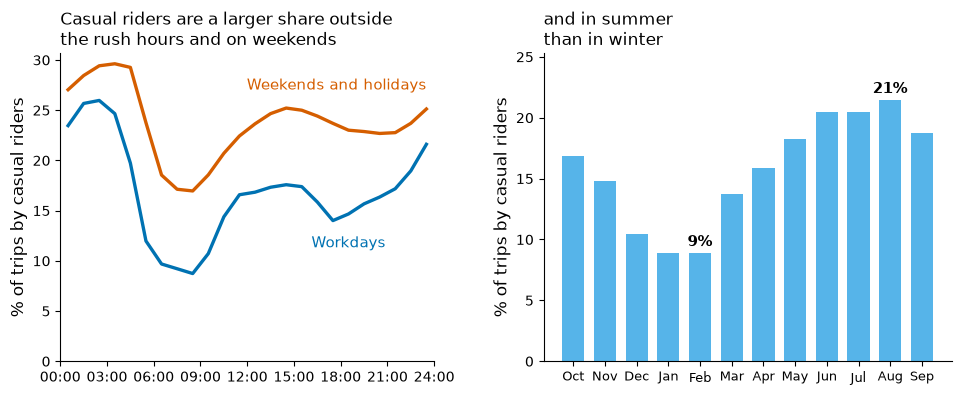

In [6]:
def fig_riders(lang):
  L = LABELS_R[lang]
  fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.0), gridspec_kw=dict(width_ratios=[1.1, 1.2]))
  ax = axes[0]
  for t, color, label in ((0, C_DEST, L['workday']), (1, C_ORIGIN, L['free'])):
    p = by_hour.loc[t]['casual_share'] * 100
    ax.plot(p.index + 0.5, p.values, color=color, lw=2.4)
    xl, off, ha = (23.5, 14, 'right') if t == 1 else (18.5, -24, 'center')
    yl = float(np.interp(xl, p.index + 0.5, p.values))
    ax.annotate(label, (xl, yl), textcoords='offset points', xytext=(0, off), ha=ha, color=color, fontsize=11)
  ax.set_xlim(0, 24)
  ax.set_xticks(range(0, 25, 3))
  ax.set_xticklabels([f'{h:02d}:00' for h in range(0, 25, 3)])
  ax.set_ylim(0, None)
  ax.set_ylabel(L['ya'])
  ax.set_title(L['ta'])
  ax = axes[1]
  ax.bar(range(12), month.casual_share * 100, color=C_RAIN, width=0.7)
  ax.set_xticks(range(12))
  ax.set_xticklabels([L['months'][int(m[5:]) - 1] for m in month.month], fontsize=9)
  hi, lo = month.casual_share.idxmax(), month.casual_share.idxmin()
  for i in (hi, lo):
    ax.text(i, month.casual_share[i] * 100 + 0.6, f'{month.casual_share[i] * 100:.0f}%', ha='center', fontsize=11, fontweight='bold')
  ax.set_ylim(0, month.casual_share.max() * 100 * 1.18)
  ax.set_title(L['tb'])
  ax.set_ylabel(L['ya'])
  fig.subplots_adjust(wspace=0.28)
  return fig


LABELS_R = {
    'en': dict(workday='Workdays', free='Weekends and holidays', ya='% of trips by casual riders', ta='Casual riders are a larger share outside\nthe rush hours and on weekends',
               tb='and in summer\nthan in winter', months=['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']),
    'es': dict(workday='Días laborables', free='Fines de semana y festivos', ya='% de viajes de ocasionales',
               ta='Los ocasionales pesan más fuera de\nlas horas pico y en fin de semana', tb='y más en verano\nque en invierno',
               months=['ene', 'feb', 'mar', 'abr', 'may', 'jun', 'jul', 'ago', 'sep', 'oct', 'nov', 'dic']),
}
for lang in ('en', 'es'):
  f = fig_riders(lang)
  f.savefig(IMG / f'findings_riders_{lang}.png')
  if lang == 'en':
    plt.show()
  plt.close(f)

## 3. How much do rain, cold and snow cut demand

City departures per hour are compared with dry hours **of the same month, day type and hour of the day** (576 fixed effects), so the season and the daily rhythm are not counted as weather.
Poisson regression with standard errors clustered by day.
Rain bins are mm in that hour: light 0 to 1, moderate 1 to 4, heavy 4 or more.
Temperature is the deviation from the mean of its stratum, so it measures a warmer or colder day than usual for that month, not the season itself.
This is observational: it describes the association in one year of data.

In [7]:
sl = data.slots
hw = sl.groupby(['fecha', 'hora']).agg(temp=('temperature_2m', 'mean'), rain=('precipitation', 'mean'), snow=('snowfall', 'mean')).reset_index()
hw['day'] = pd.DatetimeIndex(hw.fecha).map({d: i for i, d in enumerate(data.days)}).values
hw['free'] = free[hw.day.values]
hw['month'] = pd.DatetimeIndex(hw.fecha).strftime('%Y-%m').values
hw['stratum'] = hw.month + '_' + hw.free.astype(str) + '_' + hw.hora.astype(str)
hw['rain_bin'] = pd.cut(hw.rain, [-1, 0.0, 1.0, 4.0, 1e9], labels=['dry', 'light', 'moderate', 'heavy'])
hw['hgroup'] = pd.cut(hw.hora, [-1, 5, 9, 15, 19, 23], labels=['night', 'morning peak', 'midday', 'evening peak', 'late'])
hw['snowing'] = (hw.snow > 0).astype(float)
N['rain_hours'] = hw.rain_bin.value_counts().astype(int).to_dict()
N['snow_hours'] = int(hw.snowing.sum())


def city_series(select):
  c2 = city_mix[select(city_mix)].groupby(['day', 'hour'])['n'].sum().rename('y').reset_index()
  return hw.merge(c2, left_on=['day', 'hora'], right_on=['day', 'hour'], how='left').fillna({'y': 0})


def fit_weather(frame, by_group=False):
  X = pd.get_dummies(frame.stratum).astype(float)
  cols = []
  bins = ['light', 'moderate', 'heavy']
  if by_group:
    for g in ['morning peak', 'midday', 'evening peak']:
      for b in bins:
        X[f'{b}|{g}'] = ((frame.rain_bin == b) & (frame.hgroup == g)).astype(float)
        cols.append(f'{b}|{g}')
  else:
    for b in bins:
      X[b] = (frame.rain_bin == b).astype(float)
      cols.append(b)
  X['temp_10C'] = (frame.temp - frame.groupby('stratum').temp.transform('mean')) / 10
  X['snowing'] = frame.snowing
  cols += ['temp_10C', 'snowing']
  res = sm_api.GLM(frame.y, X, family=sm_api.families.Poisson()).fit(cov_type='cluster', cov_kwds={'groups': frame.day.values})
  ci_ = res.conf_int()
  return pd.DataFrame({'effect_pct': (np.exp(res.params[cols]) - 1) * 100, 'low_pct': (np.exp(ci_.loc[cols, 0]) - 1) * 100,
                       'high_pct': (np.exp(ci_.loc[cols, 1]) - 1) * 100}).rename_axis('term').reset_index()


all_trips = city_series(lambda d: d.n > -1)
fits = {'all trips': fit_weather(all_trips), 'all trips, by hour of day': fit_weather(all_trips, by_group=True)}
for name, sel in {'members': lambda d: d.member == 1, 'casual riders': lambda d: d.member == 0, 'classic bikes': lambda d: d.electric == 0,
                  'electric bikes': lambda d: d.electric == 1}.items():
  fits[name] = fit_weather(city_series(sel))
weather = pd.concat([f.assign(group=k) for k, f in fits.items()], ignore_index=True)
save(weather.round(2), 'findings_weather_effects.csv')
N['weather_all'] = fits['all trips'].set_index('term').round(1).to_dict('index')
N['weather_by_hour'] = fits['all trips, by hour of day'].set_index('term').round(1).to_dict('index')
N['weather_by_group'] = {k: fits[k].set_index('term').round(1).to_dict('index') for k in ('members', 'casual riders', 'classic bikes', 'electric bikes')}
fits['all trips'].round(1)

,term,effect_pct,low_pct,high_pct
0,light,-22.3,-26.1,-18.3
1,moderate,-47.3,-54.1,-39.4
2,heavy,-59.0,-68.8,-46.1
3,temp_10C,29.8,24.5,35.3
4,snowing,-33.1,-49.2,-11.9


## 4. Where the forecast can be trusted, and what the model adds

The shipped model (v3, refit through Sep 16) and the baseline to beat (`C|all+level`, a station profile rescaled by the recent level) are both scored on the test block, Sep 17 to 30.
Nothing in this part was used to choose a model or a threshold.

In [8]:
ds = cm.Dataset(data)
st = cm.station_inputs(data, REPO)
d_train_end, d_val_end = data.day(ce.TRAIN_END) + 1, data.day(ce.VAL[1]) + 1
test = data.block('test', *ce.TEST)
nd = test.d1 - test.d0
model, feats = cm.fit_cached(data, ds, st, 0, d_val_end, dict(epochs=16), WORK / 'final_refit.pt', log=lambda *a, **k: None)
mu, al = cm.predict(model, feats, test)
Yt, at, slt = ce.block_arrays(data, test)
Yt, at = np.asarray(Yt), np.asarray(at)
P_base, _ = ce.baseline_level_scaled(data, 'C', (0, d_val_end), test)
ref = ce.block_summary(data, 'v3 refit', mu, al, test, 'refit')
assert abs(ref['wape_day'] - 0.2086) < 5e-4, 'the model must reproduce the published test score'


def daily(a):
  return (np.asarray(a, dtype=np.float64)[..., :2].reshape(n, nd, 96, 2) * at.reshape(n, nd, 96)[..., None]).sum((0, 2, 3))


days = pd.DataFrame({'date': data.days[test.d0:test.d1].strftime('%Y-%m-%d'), 'weekday': data.days[test.d0:test.d1].strftime('%a'),
                     'actual': daily(Yt), 'v3': daily(mu), 'baseline': daily(P_base)})
rain_day = sl.iloc[test.s0:test.s1].groupby('fecha', sort=True)['precipitation'].apply(lambda s: s.sum() / 4).values
days['rain_mm'] = rain_day
days['v3_error_pct'] = (days.v3 / days.actual - 1) * 100
days['baseline_error_pct'] = (days.baseline / days.actual - 1) * 100
save(days.round(1), 'findings_test_days.csv')
wet = days.rain_mm >= 10
N['test_days'] = dict(mae_v3=float(days.v3_error_pct.abs().mean()), mae_baseline=float(days.baseline_error_pct.abs().mean()),
                      wet=days[wet][['date', 'rain_mm', 'actual', 'v3', 'baseline', 'v3_error_pct', 'baseline_error_pct']].round(1).to_dict('records'),
                      dry_v3_mean_error=float(days[days.rain_mm < 5].v3_error_pct.mean()),
                      wet_baseline_ratio_max=float((days[wet].baseline / days[wet].actual).max()),
                      wet_v3_ratio_max=float((days[wet].v3 / days[wet].actual).max()))
days.round(1)

,date,weekday,actual,v3,baseline,rain_mm,v3_error_pct,baseline_error_pct
0,2026-09-17,Thu,202973.0,175145.6,176768.2,0.200000,-13.7,-12.9
1,2026-09-18,Fri,211736.0,184608.2,176671.6,0.100000,-12.8,-16.6
2,2026-09-19,Sat,198508.0,171041.5,150883.9,0.000000,-13.8,-24.0
3,2026-09-20,Sun,87082.0,91850.4,150883.8,11.300000,5.5,73.3
4,2026-09-21,Mon,163420.0,150106.5,176486.3,2.000000,-8.1,8.0
5,2026-09-22,Tue,178160.0,158515.7,176248.0,2.100000,-11.0,-1.1
6,2026-09-23,Wed,185285.0,155582.8,175771.8,0.000000,-16.0,-5.1
7,2026-09-24,Thu,182745.0,157440.4,175656.4,0.000000,-13.8,-3.9
8,2026-09-25,Fri,170504.0,157227.1,175669.0,3.100000,-7.8,3.0
9,2026-09-26,Sat,62805.0,83456.3,150201.8,24.500000,32.9,139.2


In [9]:
# Which stations lose bikes in the morning peak of a workday? Plan: the K stations with the largest predicted loss.
work_days = np.nonzero(data.daytype[test.d0:test.d1] == 0)[0]
K = 100
full_d = at.reshape(n, nd, 96).all(2)


def am_net(a):
  x = np.asarray(a, dtype=np.float64).reshape(a.shape[0], nd, 24, 4, 4)[:, :, 6:10]
  return (x[..., 2] + x[..., 3] - x[..., 0] - x[..., 1]).sum((2, 3))


A, M_, B_ = am_net(Yt), am_net(mu), am_net(P_base)
dep_pred = np.asarray(mu, dtype=np.float64).reshape(n, nd, 96, 4)[..., :2].sum((2, 3))
res = {}
for name, P in (('v3', M_), ('baseline', B_)):
  prec, cover = [], []
  for d in work_days:
    ok = full_d[:, d] & (dep_pred[:, d] >= LOW)
    a, p = A[ok, d], P[ok, d]
    top_p = np.argsort(p)[:K]
    prec.append(len(set(np.argsort(a)[:K]) & set(top_p)) / K)
    loss = np.maximum(-a, 0)
    cover.append(loss[top_p].sum() / loss.sum())
  ok = full_d[:, work_days].all(1) & (dep_pred[:, work_days].mean(1) >= LOW)
  am, pm_ = A[ok][:, work_days].mean(1), P[ok][:, work_days].mean(1)
  bigs = np.abs(am) >= BIG
  res[name] = dict(precision_at_100=np.mean(prec), share_of_lost_bikes_covered=np.mean(cover), spearman=sps.spearmanr(am, pm_)[0],
                   direction_correct_big_movers=(np.sign(am[bigs]) == np.sign(pm_[bigs])).mean(), big_movers=int(bigs.sum()), stations=int(ok.sum()))
oracle = []
for d in work_days:
  ok = full_d[:, d] & (dep_pred[:, d] >= LOW)
  a = A[ok, d]
  loss = np.maximum(-a, 0)
  oracle.append(loss[np.argsort(a)[:K]].sum() / loss.sum())
res['perfect foresight'] = dict(share_of_lost_bikes_covered=np.mean(oracle))
reloc = pd.DataFrame(res).T.reset_index().rename(columns={'index': 'plan'})
save(reloc.round(4), 'findings_relocation_test.csv')
N['relocation'] = {r['plan']: {k: (None if pd.isna(v) else v) for k, v in r.items() if k != 'plan'} for r in reloc.round(4).to_dict('records')}
N['relocation_days'] = int(len(work_days))
reloc.round(3)

,plan,precision_at_100,share_of_lost_bikes_covered,spearman,direction_correct_big_movers,big_movers,stations
0,v3,0.742,0.348,0.949,0.988,907.0,1756.0
1,baseline,0.741,0.347,0.949,0.989,907.0,1756.0
2,perfect foresight,NaN,0.378,NaN,NaN,NaN,NaN


In [10]:
tier = ce.volume_tiers(data, 0, d_val_end)
tier_name = np.array(['no training data'] + ce.TIER_NAMES, dtype=object)[tier + 1]


def sd_series(a, level):
  x = np.asarray(a, dtype=np.float64)[..., :2].sum(-1)
  return x.reshape(n, -1, 96 if level == 'day' else 4).sum(2)


day_y = sd_series(Yt, 'day')
rows = []
for t in ce.TIER_NAMES:
  sel = tier_name == t
  r = dict(tier=t, stations=int(sel.sum()), departures_per_day=float(day_y[sel].mean()),
           share_of_trips=float(day_y[sel].sum() / day_y[tier_name != 'no training data'].sum()))
  for lv in ('hour', 'day'):
    y, m = sd_series(Yt, lv)[sel], at.reshape(n, -1, 96 if lv == 'day' else 4).all(2)[sel]
    for name, P in (('v3', mu), ('baseline', P_base)):
      r[f'wape_{lv}_{name}'] = float((np.abs(y - sd_series(P, lv)[sel]) * m).sum() / (y * m).sum())
  rows.append(r)
tiers = save(pd.DataFrame(rows).round(4), 'findings_tiers_test.csv')
N['tiers'] = tiers.set_index('tier').to_dict('index')
N['busiest'] = dict(stations=int(tiers.set_index('tier').loc['>40', 'stations']), share_of_trips=float(tiers.set_index('tier').loc['>40', 'share_of_trips']),
                    share_of_stations=float(tiers.set_index('tier').loc['>40', 'stations'] / (tier_name != 'no training data').sum()))
N['quiet'] = dict(stations=int(tiers.set_index('tier').loc[['<2', '2-5'], 'stations'].sum()), share_of_trips=float(tiers.set_index('tier').loc[['<2', '2-5'], 'share_of_trips'].sum()))
tiers

,tier,stations,departures_per_day,share_of_trips,wape_hour_v3,wape_hour_baseline,wape_day_v3,wape_day_baseline
0,<2,132,0.6185,0.0005,1.5912,1.6299,0.7517,0.7152
1,2-5,245,4.4860,0.0072,1.4400,1.5763,0.4421,0.5501
2,5-15,670,11.2014,0.0489,1.0518,1.1317,0.3152,0.4078
3,15-40,542,30.6427,0.1082,0.6874,0.7670,0.2234,0.3336
4,>40,924,138.6904,0.8352,0.3867,0.4893,0.1873,0.3136


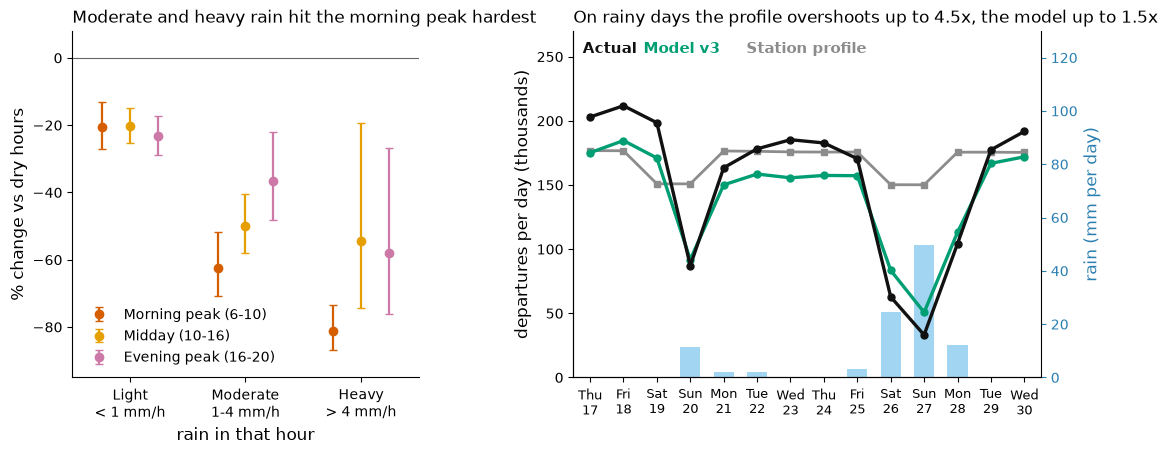

In [11]:
def fig_weather(lang):
  L = LABELS_W[lang]
  fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.5), gridspec_kw=dict(width_ratios=[1, 1.35]))
  ax = axes[0]
  g = fits['all trips, by hour of day'].set_index('term')
  groups = [('morning peak', '#D55E00', -0.24), ('midday', '#E69F00', 0.0), ('evening peak', '#CC79A7', 0.24)]
  for grp, color, off in groups:
    pts = [g.loc[f'{b}|{grp}'] for b in ('light', 'moderate', 'heavy')]
    xs = np.arange(3) + off
    ax.errorbar(xs, [p.effect_pct for p in pts], yerr=[[p.effect_pct - p.low_pct for p in pts], [p.high_pct - p.effect_pct for p in pts]], fmt='o',
                color=color, capsize=3, lw=1.6, ms=6, label=L[grp])
  ax.axhline(0, color='0.4', lw=0.8)
  ax.set_xticks(range(3))
  ax.set_xticklabels(L['bins'])
  ax.set_xlim(-0.5, 2.5)
  ax.set_ylim(-95, 8)
  ax.set_ylabel(L['ya'])
  ax.set_xlabel(L['xa'])
  ax.legend(loc='lower left', fontsize=10)
  ax.set_title(L['ta'])
  ax = axes[1]
  x = np.arange(len(days))
  ax2 = ax.twinx()
  ax2.bar(x, days.rain_mm, color=C_RAIN, alpha=0.55, width=0.6, zorder=1)
  ax2.set_ylim(0, 130)
  ax2.set_ylabel(L['yr'], color='#2a7fb0')
  ax2.spines['right'].set_visible(True)
  ax2.tick_params(axis='y', colors='#2a7fb0')
  ax.set_zorder(ax2.get_zorder() + 1)
  ax.patch.set_visible(False)
  ax.plot(x, days.baseline / 1000, color=C_BASE, lw=2, marker='s', ms=4)
  ax.plot(x, days.v3 / 1000, color=C_MODEL, lw=2.4, marker='o', ms=5)
  ax.plot(x, days.actual / 1000, color=C_ACTUAL, lw=2.4, marker='o', ms=5)
  last = len(days) - 1
  for i, (label, color) in enumerate(((L['actual'], C_ACTUAL), (L['v3'], C_MODEL), (L['baseline'], C_BASE))):
    ax.text((0.02, 0.15, 0.37)[i], 0.97, label, color=color, fontsize=11, fontweight='bold', transform=ax.transAxes, va='top')
  ax.set_xticks(x)
  ax.set_xticklabels([f"{wd}\n{d[8:]}" for wd, d in zip(days.weekday.map(L['wd']), days.date)], fontsize=9)
  ax.set_xlim(-0.5, last + 0.5)
  ax.set_ylim(0, 270)
  ax.set_ylabel(L['yb'])
  ax.set_title(L['tb'])
  fig.subplots_adjust(wspace=0.38)
  return fig


mx = N['test_days']
LABELS_W = {
    'en': {'morning peak': 'Morning peak (6-10)', 'midday': 'Midday (10-16)', 'evening peak': 'Evening peak (16-20)',
           'bins': ['Light\n< 1 mm/h', 'Moderate\n1-4 mm/h', 'Heavy\n> 4 mm/h'], 'ya': '% change vs dry hours', 'xa': 'rain in that hour',
           'ta': 'Moderate and heavy rain hit the morning peak hardest', 'yb': 'departures per day (thousands)', 'yr': 'rain (mm per day)',
           'tb': f"On rainy days the profile overshoots up to {mx['wet_baseline_ratio_max']:.1f}x, the model up to {mx['wet_v3_ratio_max']:.1f}x",
           'baseline': 'Station profile', 'v3': 'Model v3', 'actual': 'Actual', 'wd': dict(Mon='Mon', Tue='Tue', Wed='Wed', Thu='Thu', Fri='Fri', Sat='Sat', Sun='Sun')},
    'es': {'morning peak': 'Pico de la mañana (6-10)', 'midday': 'Mediodía (10-16)', 'evening peak': 'Pico de la tarde (16-20)',
           'bins': ['Ligera\n< 1 mm/h', 'Moderada\n1-4 mm/h', 'Fuerte\n> 4 mm/h'], 'ya': '% de cambio vs. horas secas', 'xa': 'lluvia en esa hora',
           'ta': 'La lluvia moderada y fuerte golpea\nmás el pico de la mañana', 'yb': 'salidas por día (miles)', 'yr': 'lluvia (mm por día)',
           'tb': f"Con lluvia el perfil se pasa hasta {mx['wet_baseline_ratio_max']:.1f}x\ny el modelo hasta {mx['wet_v3_ratio_max']:.1f}x",
           'baseline': 'Perfil de estación', 'v3': 'Modelo v3', 'actual': 'Real', 'wd': dict(Mon='lun', Tue='mar', Wed='mié', Thu='jue', Fri='vie', Sat='sáb', Sun='dom')},
}
g = fits['all trips, by hour of day'].set_index('term')
for b in ('moderate', 'heavy'):
  assert g.loc[f'{b}|morning peak', 'effect_pct'] < min(g.loc[f'{b}|midday', 'effect_pct'], g.loc[f'{b}|evening peak', 'effect_pct']), 'title claim'
for lang in ('en', 'es'):
  f = fig_weather(lang)
  f.savefig(IMG / f'findings_weather_{lang}.png')
  if lang == 'en':
    plt.show()
  plt.close(f)

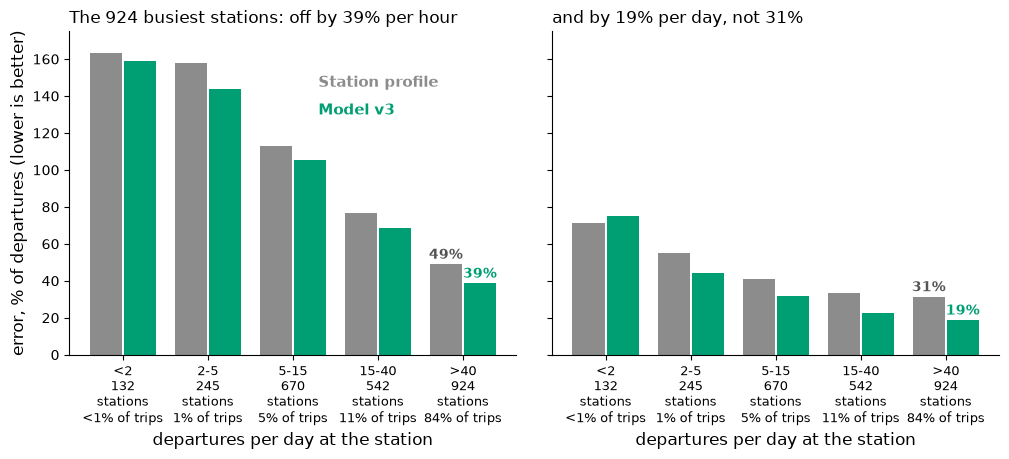

In [12]:
def fig_trust(lang):
  L = LABELS_T[lang]
  fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
  x = np.arange(len(tiers))
  labels = [f"{t.stations}\n{L['st']}\n{t.share_of_trips * 100:.0f}% {L['trips']}" if t.share_of_trips >= 0.005 else f"{t.stations}\n{L['st']}\n<1% {L['trips']}"
            for t in tiers.itertuples()]
  for ax, lv in zip(axes, ('hour', 'day')):
    ax.bar(x - 0.2, tiers[f'wape_{lv}_baseline'] * 100, width=0.38, color=C_BASE)
    ax.bar(x + 0.2, tiers[f'wape_{lv}_v3'] * 100, width=0.38, color=C_MODEL)
    top = tiers.iloc[-1]
    for xx, key, color in ((x[-1] - 0.2, 'baseline', '#555555'), (x[-1] + 0.2, 'v3', C_MODEL)):
      ax.text(xx, top[f'wape_{lv}_{key}'] * 100 + 3, f"{top[f'wape_{lv}_{key}'] * 100:.0f}%", ha='center', fontsize=10, fontweight='bold', color=color)
    ax.set_xticks(x)
    ax.set_xticklabels([f"{t.tier}\n{labels[i]}" for i, t in enumerate(tiers.itertuples())], fontsize=9)
    ax.set_title(L[f't_{lv}'].format(v3=top[f'wape_{lv}_v3'] * 100, base=top[f'wape_{lv}_baseline'] * 100, n=int(top.stations)))
    ax.set_xlabel(L['xa'])
  axes[0].set_ylabel(L['ya'])
  axes[0].text(2.3, 145, L['baseline'], color=C_BASE, fontsize=11, fontweight='bold')
  axes[0].text(2.3, 130, L['v3'], color=C_MODEL, fontsize=11, fontweight='bold')
  axes[0].set_ylim(0, 175)
  fig.subplots_adjust(wspace=0.08)
  return fig


LABELS_T = {
    'en': dict(st='stations', trips='of trips', xa='departures per day at the station', ya='error, % of departures (lower is better)',
               t_hour='The {n} busiest stations: off by {v3:.0f}% per hour', t_day='and by {v3:.0f}% per day, not {base:.0f}%', baseline='Station profile', v3='Model v3'),
    'es': dict(st='est.', trips='viajes', xa='salidas por día en la estación', ya='error, % de las salidas (menos es mejor)',
               t_hour='Las {n} estaciones más usadas: error de {v3:.0f}% por hora', t_day='y de {v3:.0f}% por día, no {base:.0f}%', baseline='Perfil de estación', v3='Modelo v3'),
}
for lang in ('en', 'es'):
  f = fig_trust(lang)
  f.savefig(IMG / f'findings_trust_{lang}.png')
  if lang == 'en':
    plt.show()
  plt.close(f)

In [13]:
def plain(o):
  if isinstance(o, dict):
    return {str(k): plain(v) for k, v in o.items()}
  if isinstance(o, (list, tuple)):
    return [plain(v) for v in o]
  if isinstance(o, (np.floating, float)):
    return None if np.isnan(o) else round(float(o), 5)
  if isinstance(o, np.integer):
    return int(o)
  return o


(RESULTS / 'findings_numbers.json').write_text(json.dumps(plain(N), indent=1, ensure_ascii=False))
print(sorted(f.name for f in RESULTS.glob('findings_*')))
print(sorted(f.name for f in IMG.glob('findings_*')))

['findings_borough.csv', 'findings_numbers.json', 'findings_relocation_test.csv', 'findings_rider_hour.csv', 'findings_rider_month.csv', 'findings_station_profiles.csv', 'findings_station_types.csv', 'findings_test_days.csv', 'findings_tiers_test.csv', 'findings_weather_effects.csv']
['findings_riders_en.png', 'findings_riders_es.png', 'findings_tide_en.png', 'findings_tide_es.png', 'findings_trust_en.png', 'findings_trust_es.png', 'findings_weather_en.png', 'findings_weather_es.png']


## Limits

- Parts 1 to 3 are associations in one year of data. The weather effects compare hours with the same month, day type and hour, but a day with heavy rain also differs in other ways that are not measured.
- The station types use round thresholds that were not tuned. A station near a threshold can change type with another year of data.
- Part 4 uses a test block of 14 days, 10 of them workdays, and its two wettest days (24.5 and 49.8 mm) are outside the range that the model saw in training for heavy rain, which is why it overshoots there.
- Trip data hold only satisfied demand: an empty station shows fewer departures than people wanted, so every net flow here is a lower bound of what was needed.
- Casual share is a share of trips, not of people.